# Figures 1 and 2 — Event Study: Privacy Patent Counts on Topic Relevance by Fiscal Year, 2017 as the Base Year

| Item | Description |
|---|---|
| Goal | The year-by-year version of the Table 2 difference-in-differences (the companion table notebook, T4.1.X - Table): the coefficient on the firm's topic relevance interacted with each fiscal year, 2017 omitted, so that the pre-2018 coefficients test parallel trends and the post-2018 coefficients trace the change after the Facebook–Cambridge Analytica revelations of March 2018. Figure 1 uses NAICS two-digit-by-year fixed effects (the requested specification); Figure 2 adds firm fixed effects. |
| Comparison | Within NAICS two-digit-by-year cells, firms one standard deviation apart in topic relevance, on the number of privacy patents filed in each year, each year's difference measured relative to the difference in 2017. |
| Unit and sample | Firm-year: the T4.1.3 analysis sample in fiscal 1999 to 2021 with a 10-K and the three lagged controls (T4.1.5; 11,406 firm-years, 685 firms). `ppmlhdfe` drops units with a zero count throughout; estimation samples are reported per figure. |
| Treated group / exposure | Continuous: the firm's topic-relevance score (T3.8.3, one score per firm), standardized over the regression firm-years, interacted with fiscal-year indicators (`c.relevance#ib2017.fyear`). The interactions are built as explicit variables so that the coefficient names carry the year. |
| Control / reference group | Less relevant firms in the same NAICS code and year; 2017 is the omitted base year, so every coefficient is the relevance gradient in that year minus the gradient in 2017. Controls at t − 1: log firm age, log total assets, log of one plus R&D expense with a missing flag. In Figure 1 the score's main effect is the 2017 gradient; in Figure 2 it is absorbed by the firm fixed effects. |
| Timing and baseline | Fiscal years 1999 to 2021, 2017 omitted; the dashed marker at 2017.5 separates the last pre-period year from the first post-period year, fiscal 2018. The count of year t is the count filed in calendar year t. |
| Outcome | KPSS patents filed in the year with at least one code of the privacy code list (T4.1.2). |
| Estimate and interpretation | Each marker is the change in the log expected privacy patent count per standard deviation of relevance in that year relative to 2017. Pre-2018 markers near zero support parallel trends; post-2018 markers above zero mean more relevant firms pulled further ahead after the revelations. A joint test that the 1999 to 2016 coefficients are zero and a joint test that the 2018 to 2021 coefficients are zero are reported in the Notes. |
| Adjustment and inference | `ppmlhdfe` with the fixed effects named per figure, standard errors clustered by firm, 95 percent intervals with the normal critical value. |
| Assumption and limits | A causal reading of the post-2018 coefficients needs that relevance would not have predicted a change in privacy patenting after 2017 for other reasons; the GDPR took effect in May 2018 and the CCPA was passed in June 2018, so the post-period bundles several privacy events. KPSS covers granted patents only, so the last years are undercounted for every firm. |
| Comparison status | Requested by the user: the parallel-trend figure for the Table 2 specification with 2017 as the base. Added: the firm-fixed-effect version as Figure 2. |
| Input | `Processed/privacy_regression_panel.dta` from T4.1.5. |
| Output | `Processed/figure_1_2_relevance_by_year_coefficients.dta` on scratch and its CSV copy in `output/X1.1.X`; `output/X1.1.X/fig_<1\|2>_privacy_patents_relevance_by_year_base_2017_<naics\|firm>_fe.{png,svg,pdf}`. |


## Step 1. Set the Stata session options

A fresh session with the Stata version, no leftover data or estimates, no paging, and a wide line.


In [0]:
version 18.5
clear all
set more off
set linesize 255


## Step 2. Define inputs and output locations

The two roots and the S5 folders as globals; the panel and the coefficient dataset on scratch, the figures in this notebook's output folder.


In [1]:
global PROJECT_FOLDER "/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis"
global SCRATCH_FOLDER "/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis"
global NOTEBOOK_SECTION "X1 - Example of Research Enabled by LLM Pipeline"
global NOTEBOOK_SUBFOLDER "${NOTEBOOK_SECTION}/X1.1 - Privacy Patents and Topic Relevance"
global NOTEBOOK_NAME "T4.1.X"
global PROCESSED_FOLDER "${SCRATCH_FOLDER}/${NOTEBOOK_SUBFOLDER}/Processed"
global FIGURE_FOLDER "${PROJECT_FOLDER}/${NOTEBOOK_SECTION}/output/${NOTEBOOK_NAME}"
global PANEL_FILE "${PROCESSED_FOLDER}/privacy_regression_panel.dta"
global COEF_FILE "${PROCESSED_FOLDER}/figure_1_2_relevance_by_year_coefficients.dta"
global CONTROLS "ln_age_l1 ln_at_l1 ln_xrd_l1 rd_missing_l1"
global YEAR_START 1999
global YEAR_END 2021
global BASE_YEAR 2017
global POST_START 2018
capture mkdir "${FIGURE_FOLDER}"
display "Panel: ${PANEL_FILE}"
display "Figure folder: ${FIGURE_FOLDER}"


Panel: /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/T4.1 - Privacy Patents and Topic Relevance/Processed/privacy_regression_panel.dta
Figure folder: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.X


## Step 3. Apply the project figure style

The S3 colors as RGB globals, the zero-line width, and the Times New Roman font for the graph window and exports.


In [2]:
global RED "179 25 66"
global BLUE "10 49 97"
global MIDNIGHT_BLUE "0 73 83"
global GREY "166 166 168"
global BLACK "16 24 32"
global ZERO_LINE_WIDTH = 0.8 / 3
graph set window fontface "Times New Roman"
graph set print fontface "Times New Roman"
graph set svg fontface "Times New Roman"
set scheme s2mono


not available in non-GUI version


## Step 4. Load the panel, restrict the sample, and define the regression variables

The Table 2 regression input: firm-years with the three lagged controls, the standardized score, the firm id, and the NAICS two-digit-by-year cell id. One interaction variable per fiscal year, the score times the year indicator; the base year's variable is built but left out of the regressions.


In [3]:
use "${PANEL_FILE}", clear
isid gvkey fyear
drop if missing(relevance_firm, ln_age_l1, ln_at_l1, ln_xrd_l1)
count
egen firm_id = group(gvkey)
egen naics2_year = group(naics2 fyear)
egen relevance_z = std(relevance_firm)
egen firm_tag = tag(gvkey)
quietly count if firm_tag
display "Firms: " r(N)
forvalues y = $YEAR_START/$YEAR_END {
    gen rel_y`y' = relevance_z * (fyear == `y')
}
quietly summarize relevance_firm
global SD_SCORE = r(sd)
display "Standard deviation of the score over the regression firm-years: " %6.4f ${SD_SCORE}
tab fyear if n_privacy_patents > 0


(58 observations deleted)
  11,406


Firms: 685
Standard deviation of the score over the regression firm-years: 0.0353

Fiscal year |      Freq.     Percent        Cum.
------------+-----------------------------------
       1999 |         38        1.89        1.89
       2000 |         60        2.98        4.87
       2001 |         72        3.57        8.44
       2002 |         65        3.23       11.67
       2003 |         56        2.78       14.45
       2004 |         66        3.28       17.73
       2005 |         70        3.48       21.20
       2006 |         72        3.57       24.78
       2007 |         69        3.43       28.20
       2008 |         73        3.62       31.83
       2009 |         73        3.62       35.45
       2010 |         79        3.92       39.37
       2011 |         80        3.97       43.35
       2012 |         85        4.22       47.57
       2013 |         95        4.72       52.28
       2014 |        108        5.36       57.65
       2015 |        114        5.6

## Step 5. Estimate the year-by-year coefficients with naics two-digit-by-year fixed effects

What this cell estimates: for each fiscal year except 2017, the change in the log expected privacy patent count per standard deviation of topic relevance in that year relative to 2017, within NAICS two-digit-by-year cells, given the lagged controls, clustered by firm. The score's main effect is included and is the gradient in the base year. Two joint tests follow: that the 18 pre-period coefficients (1999 to 2016) are zero, the parallel-trends check, and that the 4 post-period coefficients (2018 to 2021) are zero. The coefficients are saved for the figure.


In [4]:
ppmlhdfe n_privacy_patents relevance_z rel_y1999 rel_y2000 rel_y2001 rel_y2002 rel_y2003 rel_y2004 rel_y2005 rel_y2006 rel_y2007 rel_y2008 rel_y2009 rel_y2010 rel_y2011 rel_y2012 rel_y2013 rel_y2014 rel_y2015 rel_y2016 rel_y2018 rel_y2019 rel_y2020 rel_y2021 ${CONTROLS}, absorb(naics2_year) vce(cluster firm_id)
global N_naics = e(N)
global CLUSTERS_naics = e(N_clust)
summarize n_privacy_patents if e(sample)
global MEAN_naics = r(mean)
test rel_y1999 rel_y2000 rel_y2001 rel_y2002 rel_y2003 rel_y2004 rel_y2005 rel_y2006 rel_y2007 rel_y2008 rel_y2009 rel_y2010 rel_y2011 rel_y2012 rel_y2013 rel_y2014 rel_y2015 rel_y2016
global PRE_P_naics = r(p)
test rel_y2018 rel_y2019 rel_y2020 rel_y2021
global POST_P_naics = r(p)
display "Joint test, 1999 to 2016 coefficients zero: p = " %5.3f ${PRE_P_naics} "; joint test, 2018 to 2021 coefficients zero: p = " %5.3f ${POST_P_naics}
regsave rel_y1999 rel_y2000 rel_y2001 rel_y2002 rel_y2003 rel_y2004 rel_y2005 rel_y2006 rel_y2007 rel_y2008 rel_y2009 rel_y2010 rel_y2011 rel_y2012 rel_y2013 rel_y2014 rel_y2015 rel_y2016 rel_y2018 rel_y2019 rel_y2020 rel_y2021 using "${COEF_FILE}", addlabel(spec, "naics") replace


(dropped 2096 observations that are either singletons or separated by a fixed effect)


Iteration 1:   deviance = 6.6471e+04  eps = .         iters = 1    tol = 1.0e-04  min(eta) =  -6.66  P   


Iteration 2:   deviance = 4.9852e+04  eps = 3.33e-01  iters = 1    tol = 1.0e-04  min(eta) =  -7.83      


Iteration 3:   deviance = 4.7278e+04  eps = 5.45e-02  iters = 1    tol = 1.0e-04  min(eta) =  -9.33      


Iteration 4:   deviance = 4.6924e+04  eps = 7.54e-03  iters = 1    tol = 1.0e-04  min(eta) = -10.41      


Iteration 5:   deviance = 4.6868e+04  eps = 1.20e-03  iters = 1    tol = 1.0e-04  min(eta) = -11.24      


... (10 outputs left out)

-------------------------------------------------------------------------------

Absorbed degrees of freedom:


-----------------------------------------------------+
 Absorbed FE | Categories  - Redundant  = Num. Coefs |
-------------+---------------------------------------|
 naics2_year |       249           0         249     |


-----------------------------------------------------+



    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
n_privacy_~s |      9,310    3.454672    19.70093          0        586

 ( 1)  rel_y1999 = 0
 ( 2)  rel_y2000 = 0
 ( 3)  rel_y2001 = 0
 ( 4)  rel_y2002 = 0
 ( 5)  rel_y2003 = 0
 ( 6)  rel_y2004 = 0
 ( 7)  rel_y2005 = 0
 ( 8)  rel_y2006 = 0
 ( 9)  rel_y2007 = 0
 (10)  rel_y2008 = 0
 (11)  rel_y2009 = 0
 (12)  rel_y2010 = 0
 (13)  rel_y2011 = 0
 (14)  rel_y2012 = 0
 (15)  rel_y2013 = 0
 (16)  rel_y2014 = 0
 (17)  rel_y2015 = 0
 (18)  rel_y2016 = 0

           chi2( 18) =   55.72
         Prob > chi2 =    0.0000

 ( 1)  rel_y2018 = 0
 ( 2)  rel_y2019 = 0
 ( 3)  rel_y2020 = 0
 ( 4)  rel_y2021 = 0

           chi2(  4) =    8.85
         Prob > chi2 =    0.0649
Joint test, 1999 to 2016 coefficients zero: p = 0.000; joint test, 2018 to 2021 coefficients zero: p = 0.065
file /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [

## Step 6. Estimate the year-by-year coefficients with naics two-digit-by-year and firm fixed effects

What this cell estimates: for each fiscal year except 2017, the change in the log expected privacy patent count per standard deviation of topic relevance in that year relative to 2017, within NAICS two-digit-by-year cells and within firm, given the lagged controls, clustered by firm. The score's main effect is absorbed by the firm fixed effects. Two joint tests follow: that the 18 pre-period coefficients (1999 to 2016) are zero, the parallel-trends check, and that the 4 post-period coefficients (2018 to 2021) are zero. The coefficients are saved for the figure.


In [5]:
ppmlhdfe n_privacy_patents rel_y1999 rel_y2000 rel_y2001 rel_y2002 rel_y2003 rel_y2004 rel_y2005 rel_y2006 rel_y2007 rel_y2008 rel_y2009 rel_y2010 rel_y2011 rel_y2012 rel_y2013 rel_y2014 rel_y2015 rel_y2016 rel_y2018 rel_y2019 rel_y2020 rel_y2021 ${CONTROLS}, absorb(naics2_year firm_id) vce(cluster firm_id)
global N_firm = e(N)
global CLUSTERS_firm = e(N_clust)
summarize n_privacy_patents if e(sample)
global MEAN_firm = r(mean)
test rel_y1999 rel_y2000 rel_y2001 rel_y2002 rel_y2003 rel_y2004 rel_y2005 rel_y2006 rel_y2007 rel_y2008 rel_y2009 rel_y2010 rel_y2011 rel_y2012 rel_y2013 rel_y2014 rel_y2015 rel_y2016
global PRE_P_firm = r(p)
test rel_y2018 rel_y2019 rel_y2020 rel_y2021
global POST_P_firm = r(p)
display "Joint test, 1999 to 2016 coefficients zero: p = " %5.3f ${PRE_P_firm} "; joint test, 2018 to 2021 coefficients zero: p = " %5.3f ${POST_P_firm}
regsave rel_y1999 rel_y2000 rel_y2001 rel_y2002 rel_y2003 rel_y2004 rel_y2005 rel_y2006 rel_y2007 rel_y2008 rel_y2009 rel_y2010 rel_y2011 rel_y2012 rel_y2013 rel_y2014 rel_y2015 rel_y2016 rel_y2018 rel_y2019 rel_y2020 rel_y2021 using "${COEF_FILE}", addlabel(spec, "firm") append


(dropped 6940 observations that are either singletons or separated by a fixed effect)


 $$ Stopping (no negative residuals); separation found in 0 observations (1 iterations and 18 subiterations)


Iteration 1:   deviance = 1.6779e+04  eps = .         iters = 6    tol = 1.0e-04  min(eta) =  -4.21  P   


Iteration 2:   deviance = 1.0272e+04  eps = 6.33e-01  iters = 5    tol = 1.0e-04  min(eta) =  -5.62      


Iteration 3:   deviance = 9.0420e+03  eps = 1.36e-01  iters = 5    tol = 1.0e-04  min(eta) =  -7.31      


Iteration 4:   deviance = 8.8229e+03  eps = 2.48e-02  iters = 5    tol = 1.0e-04  min(eta) =  -8.52      


... (5 outputs left out)

Iteration 10:  deviance = 8.7944e+03  eps = 0.00e+00  iters = 3    tol = 1.0e-09  min(eta) =  -9.57   S O
------------------------------------------------------------------------------------------------------------
(legend: p: exact partial-out   s: exact solver   h: step-halving   o: epsilon below tolerance)
Converged in 10 iterations and 40 HDFE sub-iterations (tol = 1.0e-08)



HDFE PPML regression                              No. of obs      =      4,466
Absorbing 2 HDFE groups                           Residual df     =        257
Statistics robust to heteroskedasticity           Wald chi2(26)   =     110.59
Deviance             =  8794.366283               Prob > chi2     =     0.0000
Log pseudolikelihood =  -7820.46177               Pseudo R2       =     0.8862

Number of clusters (firm_id)=        258
                               (Std. err. adjusted for 258 clusters in firm_id)
-------------------------------------------------------------------------------
              |               Robust
n_privacy_p~s | Coefficient  std. err.      z    P>|z|     [95% conf. interval]
--------------+----------------------------------------------------------------
    rel_y1999 |  -.1560364   .1818135    -0.86   0.391    -.5123844    .2003116
    rel_y2000 |  -.1560438   .1764397    -0.88   0.376    -.5018593    .1897717
    rel_y2001 |  -.0005466    .137289    -0.0

-----------------------------------------------------+
 Absorbed FE | Categories  - Redundant  = Num. Coefs |
-------------+---------------------------------------|
 naics2_year |       239           1         238     |
     firm_id |       258         258           0    *|
-----------------------------------------------------+
* = FE nested within cluster; treated as redundant for DoF computation

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
n_privacy_~s |      4,466     7.19906    27.96858          0        586

 ( 1)  rel_y1999 = 0
 ( 2)  rel_y2000 = 0
 ( 3)  rel_y2001 = 0
 ( 4)  rel_y2002 = 0
 ( 5)  rel_y2003 = 0
 ( 6)  rel_y2004 = 0
 ( 7)  rel_y2005 = 0
 ( 8)  rel_y2006 = 0
 ( 9)  rel_y2007 = 0
 (10)  rel_y2008 = 0
 (11)  rel_y2009 = 0
 (12)  rel_y2010 = 0
 (13)  rel_y2011 = 0
 (14)  rel_y2012 = 0
 (15)  rel_y2013 = 0
 (16)  rel_y2014 = 0
 (17)  rel_y2015 = 0
 (18)  rel_y2016 = 0

  

file /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/T4.1 - Privacy Patents and Topic Relevance/Processed/figure_1_2_relevance_by_year_coefficients.dta saved


## Step 7. Assemble the coefficient dataset

The saved coefficients are mapped from their variable names (which end in the four-digit fiscal year) to years, the omitted year 2017 is added at zero for each specification, and the 95 percent interval is formed with the normal critical value. The panel is no longer needed, so the coefficient dataset replaces it in memory.


In [6]:
use "${COEF_FILE}", clear
gen year = real(substr(var, -4, 4))
assert !missing(year) & inrange(year, ${YEAR_START}, ${YEAR_END})
local n = _N
set obs `=`n' + 2'
replace spec = "naics" in `=`n' + 1'
replace spec = "firm" in `=`n' + 2'
replace var = "omitted" in `=`n' + 1'/`=`n' + 2'
replace coef = 0 in `=`n' + 1'/`=`n' + 2'
replace stderr = 0 in `=`n' + 1'/`=`n' + 2'
replace year = ${BASE_YEAR} in `=`n' + 1'/`=`n' + 2'
gen lower = coef - 1.96 * stderr
gen upper = coef + 1.96 * stderr
sort spec year
assert _N == 2 * (${YEAR_END} - ${YEAR_START} + 1)
list spec year coef stderr lower upper, noobs
save "${COEF_FILE}", replace
export delimited using "${FIGURE_FOLDER}/figure_1_2_relevance_by_year_coefficients.csv", replace


Number of observations (_N) was 44, now 46.
(1 real change made)
(1 real change made)
(2 real changes made)
(2 real changes made)
(2 real changes made)
(2 real changes made)

  +------------------------------------------------------------+
  |  spec   year        coef     stderr       lower      upper |
  |------------------------------------------------------------|
  |  firm   1999   -.1560364   .1818135    -.512391   .2003181 |
  |  firm   2000   -.1560438   .1764397   -.5018657    .189778 |
  |  firm   2001   -.0005466    .137289   -.2696331   .2685398 |
  |  firm   2002    .0249293   .1359964   -.2416237   .2914822 |
  |  firm   2003    .2289079   .1600247   -.0847405   .5425563 |
  |------------------------------------------------------------|
  |  firm   2004    .3067635   .2129279   -.1105752   .7241021 |
  |  firm   2005    .4337359    .217907    .0066382   .8608337 |
  |  firm   2006    .2975377   .1315196    .0397592   .5553162 |
  |  firm   2007    .1659701   .1380716   -.1

file /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.X/figure_1_2_relevance_by_year_coefficients.csv saved


## Step 8. Figure 1: draw the year-by-year coefficients with naics two-digit-by-year fixed effects, display them, and export the figure

One panel: filing year on the horizontal axis, the coefficient for each year in RED with its 95 percent interval in RED at 50 percent opacity, 2017 at zero, a solid BLACK zero line, and a dashed BLACK line at 2017.5. One substantive series, so no legend. The Y-title is pulled next to the tick labels with a negative `titlegap`, because Stata otherwise leaves about 0.6 inch of blank space there. Exported as PNG, SVG, and PDF; the title, Notes, and Source are printed around the image.


Fontconfig warning: We will not regenerate the cache because some cache files were generated by a newer version (0x2012003) of Fontconfig. Please regenerate the cache with the latest version of Fontconfig to avoid any unexpected behavior. (current version: 0x2012002)


file /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.X/fig_1_privacy_patents_relevance_by_year_base_2017_naics_fe.png written in PNG format


file /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.X/fig_1_privacy_patents_relevance_by_year_base_2017_naics_fe.svg saved as SVG format
file /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.X/fig_1_privacy_patents_relevance_by_year_base_2017_naics_fe.pdf saved as PDF format

**Figure 1. Privacy Patent Counts on Topic Relevance by Fiscal Year Relative to 2017, Poisson Estimates With NAICS Two-Digit-by-Year Fixed Effects and Lagged Controls**

*Notes*: Each marker is the coefficient on topic relevance × fiscal year from a Poisson pseudo-maximum-likelihood regression (ppmlhdfe) of the number of KPSS patents filed in year t that carry at least one CPC code of the project's privacy code list (T4.1
> .2) on these interactions, the score's main effect (the gradient in the base year), and the t − 1 controls (log firm ag

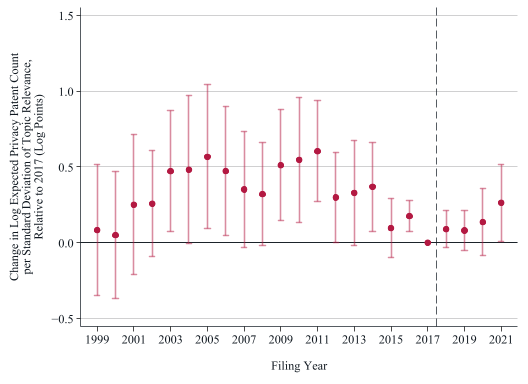

In [7]:
local figure_title "Figure 1. Privacy Patent Counts on Topic Relevance by Fiscal Year Relative to 2017, Poisson Estimates With NAICS Two-Digit-by-Year Fixed Effects and Lagged Controls"
quietly summarize lower if spec == "naics"
local y_min = floor(r(min) * 2) / 2
quietly summarize upper if spec == "naics"
local y_max = ceil(r(max) * 2) / 2
local step = cond(`y_max' - `y_min' > 3, 1, 0.5)
local y_labels ""
forvalues y = `y_min'(`step')`=`y_max' + 0.001' {
    local y = round(`y', `step')
    if abs(`y') < 0.0001 {
        local y = 0
    }
    local text = subinstr(string(`y', "%9.1f"), "-", "−", 1)
    local y_labels `"`y_labels' `y' "`text'""'
}
twoway (rcap lower upper year if spec == "naics", lcolor("${RED}%50") lwidth(medthick)) ///
       (scatter coef year if spec == "naics", mcolor("${RED}") msymbol(circle) msize(medium)), ///
    yline(0, lcolor("${BLACK}") lwidth(${ZERO_LINE_WIDTH}) lpattern(solid)) ///
    xline(`=${BASE_YEAR} + 0.5', lcolor("${BLACK}") lpattern(dash) lwidth(thin)) ///
    xlabel(${YEAR_START}(2)${YEAR_END}, labcolor("${BLACK}") nogrid) ///
    ylabel(`y_labels', angle(horizontal) labcolor("${BLACK}") glcolor("${GREY}") glwidth(vthin) gmin gmax) ///
    xscale(range(`=${YEAR_START} - 0.5' `=${YEAR_END} + 0.5') lcolor("${BLACK}")) yscale(lcolor("${BLACK}") titlegap(-5)) ///
    xtitle("Filing Year", color("${BLACK}") margin(t=3)) ///
    ytitle("Change in Log Expected Privacy Patent Count" "per Standard Deviation of Topic Relevance," "Relative to ${BASE_YEAR} (Log Points)", color("${BLACK}") size(medsmall) margin(zero)) ///
    legend(off) graphregion(color(white) margin(l=2 r=3 t=2 b=2)) plotregion(color(white) margin(l=2 r=2 t=2 b=2)) ///
    xsize(9) ysize(6) name(figure_1, replace)
graph export "${FIGURE_FOLDER}/fig_1_privacy_patents_relevance_by_year_base_2017_naics_fe.png", as(png) width(2700) height(1800) replace
graph export "${FIGURE_FOLDER}/fig_1_privacy_patents_relevance_by_year_base_2017_naics_fe.svg", as(svg) replace
graph export "${FIGURE_FOLDER}/fig_1_privacy_patents_relevance_by_year_base_2017_naics_fe.pdf", as(pdf) replace
local pre_text = cond(${PRE_P_naics} < 0.001, "< 0.001", "= " + string(${PRE_P_naics}, "%5.3f"))
local post_text = cond(${POST_P_naics} < 0.001, "< 0.001", "= " + string(${POST_P_naics}, "%5.3f"))
local n_text = string(${N_naics}, "%12.0fc")
local c_text = string(${CLUSTERS_naics}, "%12.0fc")
local m_text = string(${MEAN_naics}, "%9.3f")
local post_rows ""
forvalues y = ${POST_START}/${YEAR_END} {
    quietly summarize coef if spec == "naics" & year == `y'
    local b = r(mean)
    quietly summarize stderr if spec == "naics" & year == `y'
    local post_rows "`post_rows'`=cond(`y' > ${POST_START}, ", ", "")'`y' `=subinstr(string(`b', "%6.3f"), "-", "−", 1)' (`=string(r(mean), "%6.3f")')"
}
display _n "**`figure_title'**" _n
display "*Notes*: Each marker is the coefficient on topic relevance × fiscal year from a Poisson pseudo-maximum-likelihood regression (ppmlhdfe) of the number of KPSS patents filed in year t that carry at least one CPC code of the project's privacy code list (T4.1.2) on these interactions, the score's main effect (the gradient in the base year), and the t − 1 controls (log firm age, log total assets, log of one plus R&D expense with a missing indicator), with NAICS two-digit-by-year fixed effects absorbed; bars are 95 percent confidence intervals from standard errors clustered by firm, using the normal critical value. Topic relevance is the firm's score, the cosine similarity between a firm-level summary of its 10-K Item 1 sections and the policy summary of legislator statements on consumer data privacy legislation (T3.8.3), one score per firm, standardized over the regression firm-years (standard deviation " %6.4f ${SD_SCORE} "). The horizontal axis is the filing year of the patents, matched to the firm's fiscal year as in T4.1.5. The interaction for ${BASE_YEAR} is omitted and drawn at zero, so each coefficient is the change in the log expected count per standard deviation of relevance in that year relative to ${BASE_YEAR}; the dashed line at ${BASE_YEAR}.5 separates the last pre-period year from fiscal ${POST_START}, the first year after the Facebook–Cambridge Analytica revelations of March 2018. The joint test that the coefficients for ${YEAR_START} to `=${BASE_YEAR} - 1' are zero has p `pre_text'; the joint test that the coefficients for ${POST_START} to ${YEAR_END} are zero has p `post_text'. Post-period coefficients: `post_rows'. Estimation sample: `n_text' firm-years of the T4.1.3 analysis sample, fiscal ${YEAR_START} to ${YEAR_END}, with the lagged controls observed, after dropping units with no privacy patent in any year; `c_text' firms; mean of the dependent variable `m_text'." _n
display "*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with CPC codes; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; SEC EDGAR 10-K filings; congressional hearing statements from GovInfo; Compustat; CRSP-Compustat link; authors' calculations."


## Step 9. Figure 2: draw the year-by-year coefficients with naics two-digit-by-year and firm fixed effects, display them, and export the figure

One panel: filing year on the horizontal axis, the coefficient for each year in RED with its 95 percent interval in RED at 50 percent opacity, 2017 at zero, a solid BLACK zero line, and a dashed BLACK line at 2017.5. One substantive series, so no legend. The Y-title is pulled next to the tick labels with a negative `titlegap`, because Stata otherwise leaves about 0.6 inch of blank space there. Exported as PNG, SVG, and PDF; the title, Notes, and Source are printed around the image.


file /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.X/fig_2_privacy_patents_relevance_by_year_base_2017_firm_fe.png written in PNG format


file /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.X/fig_2_privacy_patents_relevance_by_year_base_2017_firm_fe.svg saved as SVG format
file /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.X/fig_2_privacy_patents_relevance_by_year_base_2017_firm_fe.pdf saved as PDF format

**Figure 2. Privacy Patent Counts on Topic Relevance by Fiscal Year Relative to 2017, Poisson Estimates With NAICS Two-Digit-by-Year and Firm Fixed Effects and Lagged Controls**

*Notes*: Each marker is the coefficient on topic relevance × fiscal year from a Poisson pseudo-maximum-likelihood regression (ppmlhdfe) of the number of KPSS patents filed in year t that carry at least one CPC code of the project's privacy code list (T4.1
> .2) on these interactions, and the t − 1 controls (log firm age, log total assets, log of one plus R&D expense w

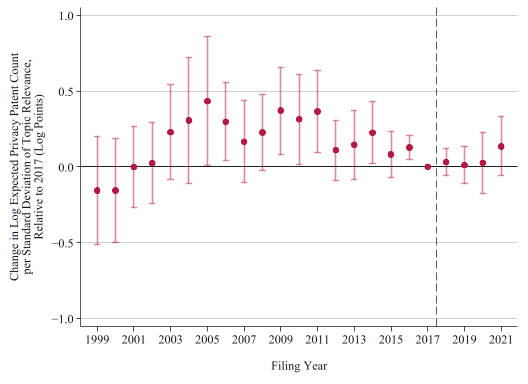

In [8]:
local figure_title "Figure 2. Privacy Patent Counts on Topic Relevance by Fiscal Year Relative to 2017, Poisson Estimates With NAICS Two-Digit-by-Year and Firm Fixed Effects and Lagged Controls"
quietly summarize lower if spec == "firm"
local y_min = floor(r(min) * 2) / 2
quietly summarize upper if spec == "firm"
local y_max = ceil(r(max) * 2) / 2
local step = cond(`y_max' - `y_min' > 3, 1, 0.5)
local y_labels ""
forvalues y = `y_min'(`step')`=`y_max' + 0.001' {
    local y = round(`y', `step')
    if abs(`y') < 0.0001 {
        local y = 0
    }
    local text = subinstr(string(`y', "%9.1f"), "-", "−", 1)
    local y_labels `"`y_labels' `y' "`text'""'
}
twoway (rcap lower upper year if spec == "firm", lcolor("${RED}%50") lwidth(medthick)) ///
       (scatter coef year if spec == "firm", mcolor("${RED}") msymbol(circle) msize(medium)), ///
    yline(0, lcolor("${BLACK}") lwidth(${ZERO_LINE_WIDTH}) lpattern(solid)) ///
    xline(`=${BASE_YEAR} + 0.5', lcolor("${BLACK}") lpattern(dash) lwidth(thin)) ///
    xlabel(${YEAR_START}(2)${YEAR_END}, labcolor("${BLACK}") nogrid) ///
    ylabel(`y_labels', angle(horizontal) labcolor("${BLACK}") glcolor("${GREY}") glwidth(vthin) gmin gmax) ///
    xscale(range(`=${YEAR_START} - 0.5' `=${YEAR_END} + 0.5') lcolor("${BLACK}")) yscale(lcolor("${BLACK}") titlegap(-5)) ///
    xtitle("Filing Year", color("${BLACK}") margin(t=3)) ///
    ytitle("Change in Log Expected Privacy Patent Count" "per Standard Deviation of Topic Relevance," "Relative to ${BASE_YEAR} (Log Points)", color("${BLACK}") size(medsmall) margin(zero)) ///
    legend(off) graphregion(color(white) margin(l=2 r=3 t=2 b=2)) plotregion(color(white) margin(l=2 r=2 t=2 b=2)) ///
    xsize(9) ysize(6) name(figure_2, replace)
graph export "${FIGURE_FOLDER}/fig_2_privacy_patents_relevance_by_year_base_2017_firm_fe.png", as(png) width(2700) height(1800) replace
graph export "${FIGURE_FOLDER}/fig_2_privacy_patents_relevance_by_year_base_2017_firm_fe.svg", as(svg) replace
graph export "${FIGURE_FOLDER}/fig_2_privacy_patents_relevance_by_year_base_2017_firm_fe.pdf", as(pdf) replace
local pre_text = cond(${PRE_P_firm} < 0.001, "< 0.001", "= " + string(${PRE_P_firm}, "%5.3f"))
local post_text = cond(${POST_P_firm} < 0.001, "< 0.001", "= " + string(${POST_P_firm}, "%5.3f"))
local n_text = string(${N_firm}, "%12.0fc")
local c_text = string(${CLUSTERS_firm}, "%12.0fc")
local m_text = string(${MEAN_firm}, "%9.3f")
local post_rows ""
forvalues y = ${POST_START}/${YEAR_END} {
    quietly summarize coef if spec == "firm" & year == `y'
    local b = r(mean)
    quietly summarize stderr if spec == "firm" & year == `y'
    local post_rows "`post_rows'`=cond(`y' > ${POST_START}, ", ", "")'`y' `=subinstr(string(`b', "%6.3f"), "-", "−", 1)' (`=string(r(mean), "%6.3f")')"
}
display _n "**`figure_title'**" _n
display "*Notes*: Each marker is the coefficient on topic relevance × fiscal year from a Poisson pseudo-maximum-likelihood regression (ppmlhdfe) of the number of KPSS patents filed in year t that carry at least one CPC code of the project's privacy code list (T4.1.2) on these interactions, and the t − 1 controls (log firm age, log total assets, log of one plus R&D expense with a missing indicator), with NAICS two-digit-by-year and firm fixed effects absorbed; bars are 95 percent confidence intervals from standard errors clustered by firm, using the normal critical value. Topic relevance is the firm's score, the cosine similarity between a firm-level summary of its 10-K Item 1 sections and the policy summary of legislator statements on consumer data privacy legislation (T3.8.3), one score per firm, standardized over the regression firm-years (standard deviation " %6.4f ${SD_SCORE} "). The horizontal axis is the filing year of the patents, matched to the firm's fiscal year as in T4.1.5. The interaction for ${BASE_YEAR} is omitted and drawn at zero, so each coefficient is the change in the log expected count per standard deviation of relevance in that year relative to ${BASE_YEAR}; the dashed line at ${BASE_YEAR}.5 separates the last pre-period year from fiscal ${POST_START}, the first year after the Facebook–Cambridge Analytica revelations of March 2018. The joint test that the coefficients for ${YEAR_START} to `=${BASE_YEAR} - 1' are zero has p `pre_text'; the joint test that the coefficients for ${POST_START} to ${YEAR_END} are zero has p `post_text'. Post-period coefficients: `post_rows'. Estimation sample: `n_text' firm-years of the T4.1.3 analysis sample, fiscal ${YEAR_START} to ${YEAR_END}, with the lagged controls observed, after dropping units with no privacy patent in any year; `c_text' firms; mean of the dependent variable `m_text'." _n
display "*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with CPC codes; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; SEC EDGAR 10-K filings; congressional hearing statements from GovInfo; Compustat; CRSP-Compustat link; authors' calculations."
